# Adaptive Dyslexia EEG Pipeline (Synthetic Demo)
Unlike a fixed-shape pipeline, this one **inspects each recording and adapts to it**:
channel names/count, sampling rate, units, mains frequency, bad channels and recording length
are detected automatically, and every decision is reported back to you.

How it stays montage-agnostic: features are computed per **scalp region** (frontal/central/temporal/
parietal/occipital x left/right + midline) rather than per electrode, so the feature vector has a
fixed length for any montage. Regions an electrode set doesn't cover become missing values, and the
model is *trained on a mix of montages* so it has learned to cope with that.

**Note:** all data is synthetic. This demonstrates the engineering, not a validated diagnostic model.

## 0. Imports & Configuration

In [1]:
import importlib
import pickle
import subprocess
import sys
import tempfile
import zipfile
from pathlib import Path

import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
rng = np.random.default_rng(SEED)

N_SUBJECTS = 360                          # synthetic subjects (one recording each), balanced classes
EFFECT = 0.30                             # strength of the simulated group difference
FS_CHOICES = [128, 250, 256, 500, 512, 1000]   # sampling rates used for the synthetic recordings
DURATION_CHOICES_S = [24, 32, 40]

OUT_DIR = Path.cwd()                      # everything is written to the local Jupyter working directory
MODULE_PATH = OUT_DIR / "eeg_adaptive.py"
CLEANING_PATH = OUT_DIR / "cleaning_model.pkl"
IDENTIFICATION_PATH = OUT_DIR / "identification_model.pkl"
EXPLANATION_PATH = OUT_DIR / "explanation.txt"
ZIP_PATH = OUT_DIR / "dyslexia_pipeline_package.zip"

## 1. The Adaptive Pipeline Module
All reusable logic (auto-detection, preprocessing, features, inference) lives in one module,
`eeg_adaptive.py`, written to disk by this cell. It is bundled in the final ZIP, so the package is
self-contained: unzip it anywhere and `predict_dyslexia(...)` works.

In [2]:
MODULE_SRC = r'''"""eeg_adaptive.py - montage-, sampling-rate- and unit-agnostic EEG preprocessing,
feature extraction and inference for the dyslexia demo pipeline.

Every automatic decision (units, mains frequency, bad channels, resampling...) is returned in a report.
"""
import pickle
import re
from fractions import Fraction
from pathlib import Path

import numpy as np
from scipy import signal

TARGET_FS = 250.0                  # every recording is resampled to this rate
EPOCH_S = 4.0                      # epoch length in seconds
BANDPASS = (1.0, 45.0)
MIN_FS = 100.0                     # need Nyquist comfortably above 45 Hz
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 45)}
LABEL_NAMES = {0: "Control", 1: "Dyslexic"}

# Scalp regions: lobe x hemisphere (odd = left, even = right) plus midline ("z") electrodes
REGIONS = ["F_L", "F_R", "C_L", "C_R", "T_L", "T_R", "P_L", "P_R", "O_L", "O_R", "MID"]
LOBES = ["F", "C", "T", "P", "O"]
_LOBE_OF_PREFIX = {"FP": "F", "AF": "F", "F": "F", "FC": "C", "C": "C", "FT": "T", "T": "T",
                   "TP": "T", "CP": "P", "P": "P", "PO": "O", "O": "O"}
_LEGACY = {"T3": "T7", "T4": "T8", "T5": "P7", "T6": "P8"}     # old 10-20 names -> 10-10 names
_NAME_RE = re.compile(r"([A-Z]{1,2})(\d{1,2}|Z)")


# ----------------------------------------------------------------------------- channel handling
def normalize_channel_name(name):
    """'EEG Fp1-REF' / 'FP1' / 'Fp1.' -> 'FP1'; old T3/T4/T5/T6 -> T7/T8/P7/P8; None if not a scalp EEG label."""
    s = str(name).strip().upper()
    s = re.sub(r"^EEG[\s_:\-]*", "", s)
    s = re.split(r"[\s_\-/.]", s)[0]
    s = _LEGACY.get(s, s)
    m = _NAME_RE.fullmatch(s)
    if m is None or m.group(1) not in _LOBE_OF_PREFIX:
        return None
    return s


def channel_region(canon):
    """Map a normalised electrode label to one of REGIONS."""
    prefix, idx = _NAME_RE.fullmatch(canon).groups()
    if idx == "Z":
        return "MID"
    return f"{_LOBE_OF_PREFIX[prefix]}_{'L' if int(idx) % 2 else 'R'}"


def _name_route(ch_names):
    """Recognise scalp electrodes by label (drops EOG/ECG/ACC/triggers/A1/A2/duplicates)."""
    keep, canon, dropped, seen = [], [], [], set()
    for i, name in enumerate(ch_names):
        c = normalize_channel_name(name)
        if c is None or c in seen:
            dropped.append(str(name))
            continue
        keep.append(i)
        canon.append(c)
        seen.add(c)
    return keep, canon, dropped


# Numbered / unnamed nets (EGI E1..E128, BioSemi A1.., custom caps) are placed by 3-D electrode position:
# each electrode is matched to the nearest 10-10 scalp site, which gives it a region. Electrodes far from any
# site (face, neck, ear sensors) are dropped.
_MAX_SITE_DISTANCE = 0.38      # unit-sphere distance to the nearest 10-10 site
_SITE_CACHE = {}
_SKIP_MONTAGES = ("standard", "fsaverage", "colin27", "spherical")     # 10-20-style names: handled by the name route


def _unit_sphere(xyz):
    """Least-squares sphere fit, then centre and scale the points to a unit sphere."""
    xyz = np.asarray(xyz, dtype=float)
    sol = np.linalg.lstsq(np.c_[2 * xyz, np.ones(len(xyz))], (xyz ** 2).sum(axis=1), rcond=None)[0]
    centre = sol[:3]
    return (xyz - centre) / np.sqrt(sol[3] + centre @ centre)


def _reference_sites():
    """10-10 scalp sites (without the lower 9/10 ring and inion sites) as (labels, unit-sphere coordinates)."""
    if "sites" not in _SITE_CACHE:
        import mne
        pos = mne.channels.make_standard_montage("standard_1005").get_positions()["ch_pos"]
        names = list(pos)
        xyz = _unit_sphere([pos[n] for n in names])
        keep = [i for i, n in enumerate(names) if normalize_channel_name(n) and not re.search(r"(9|10)$", n)]
        _SITE_CACHE["sites"] = ([normalize_channel_name(names[i]) for i in keep], xyz[keep])
    return _SITE_CACHE["sites"]


def _bare_name(name):
    """Strip recording-system decorations before matching a standard net: 'EEG A1-REF' -> 'A1', 'E12 ' -> 'E12'."""
    s = re.sub(r"^(EEG|EXG)[\s_:\-]*", "", str(name).strip(), flags=re.IGNORECASE)
    return re.split(r"[\s_/\-]", s)[0]


def _builtin_montage_positions(ch_names):
    """Find the built-in MNE montage (EGI GSN, BioSemi, EasyCap...) whose channel names best match ch_names.
    Names are compared after removing prefixes and reference suffixes, so 'EEG A1-REF' matches BioSemi 'A1'."""
    import mne
    wanted = set(_bare_name(n) for n in ch_names)
    best, best_score = None, 0.0
    for name in mne.channels.get_builtin_montages():
        if name.startswith(_SKIP_MONTAGES):
            continue
        montage = mne.channels.make_standard_montage(name)
        have = set(montage.ch_names)
        if len(wanted & have) < 0.8 * len(wanted):
            continue
        score = len(wanted & have) / len(wanted | have)
        if score > best_score:
            best, best_score = (name, montage.get_positions()["ch_pos"]), score
    return best


def _position_route(ch_names, ch_pos, min_regions):
    try:
        found = _builtin_montage_positions(ch_names)
        pos, method = None, None
        if found:
            bare = {n: _bare_name(n) for n in ch_names}
            pos = {n: found[1][bare[n]] for n in ch_names if bare[n] in found[1]}
            method = f"MNE montage '{found[0]}' (3-D electrode positions, matched by channel names)"
        elif ch_pos:
            usable = [n for n in ch_names if n in ch_pos and np.all(np.isfinite(ch_pos[n]))]
            if len(usable) >= 0.8 * len(ch_names):
                pos, method = ch_pos, "3-D electrode positions stored in the file (assumed x right, y front, z up)"
        if pos is None:
            return None
        idx = [i for i, n in enumerate(ch_names) if n in pos and np.all(np.isfinite(pos[n]))]
        if len(idx) < 16:                              # too few points for a stable sphere fit
            return None
        xyz = _unit_sphere([pos[ch_names[i]] for i in idx])
        site_names, site_xyz = _reference_sites()
    except ImportError:                                # MNE not installed
        return None
    dist_all = np.linalg.norm(xyz[:, None, :] - site_xyz[None, :, :], axis=-1)
    nearest, dist = dist_all.argmin(axis=1), dist_all.min(axis=1)
    ok = dist <= _MAX_SITE_DISTANCE
    keep = [i for i, o in zip(idx, ok) if o]
    canon = [site_names[k] for k, o in zip(nearest, ok) if o]
    if len({channel_region(c) for c in canon}) < min_regions:
        return None
    kept = set(keep)
    return keep, canon, [str(n) for i, n in enumerate(ch_names) if i not in kept], method


def resolve_channels(ch_names, ch_pos=None, min_regions=4):
    """Decide which rows are scalp EEG and which 10-10 site each belongs to.

    Returns (row indices to keep, site label per kept row, names dropped, how the decision was made).
    Order: channel labels first; if they do not identify the scalp (e.g. E1..E128), 3-D positions.
    """
    ch_names = [str(n) for n in ch_names]
    keep, canon, dropped = _name_route(ch_names)
    name_regions = {channel_region(c) for c in canon}
    if len(name_regions) >= min_regions and len(canon) >= 0.5 * len(ch_names):
        return keep, canon, dropped, "channel names"
    placed = _position_route(ch_names, ch_pos, min_regions)
    if placed is not None:
        return placed
    if len(name_regions) >= min_regions:
        return keep, canon, dropped, "channel names"
    if canon:
        raise ValueError(f"only {len(name_regions)} scalp regions could be identified from the channel names "
                         f"({sorted(name_regions)}); need at least {min_regions}. "
                         "Pass ch_names=[...] with standard 10-20/10-10 labels.")
    raise ValueError(f"None of the {len(ch_names)} channel names look like 10-20/10-10 electrode labels "
                     "(e.g. 'Fp1', 'C3', 'Oz'), and electrode positions could not be determined (standard nets "
                     "such as EGI GSN HydroCel or BioSemi are recognised by channel names when MNE is installed; "
                     "otherwise the file must store electrode coordinates). "
                     "Pass ch_names=[...] with a standard label for each row.")


# ----------------------------------------------------------------------------- auto-detection helpers
def to_microvolts(data, units="auto"):
    """Return (data in microvolts, description). 'auto' guesses volts vs microvolts from signal size."""
    if units == "uV":
        return data, "uV (given)"
    if units == "V":
        return data * 1e6, "V (given)"
    if units != "auto":
        raise ValueError("units must be 'auto', 'V' or 'uV'")
    med_sd = float(np.median(data.std(axis=1)))
    if med_sd < 1e-2:
        return data * 1e6, "V (auto-detected)"
    if med_sd < 1e4:
        return data, "uV (auto-detected)"
    return data, "unknown scale, e.g. raw ADC counts (features are scale-free, so this is harmless)"


def detect_mains(data, fs, ratio_threshold=3.0):
    """Return 50.0, 60.0 or None, based on a narrow spectral peak vs its neighbouring frequencies."""
    if fs < 110:
        return None
    freqs, psd = signal.welch(data, fs=fs, nperseg=int(min(data.shape[1], 4 * fs)), axis=-1)
    psd = np.median(psd, axis=0)
    best, best_ratio = None, ratio_threshold
    for f0 in (50.0, 60.0):
        if f0 + 1.0 >= fs / 2:
            continue
        line = (freqs >= f0 - 0.75) & (freqs <= f0 + 0.75)
        side = ((freqs >= f0 - 6) & (freqs <= f0 - 3)) | ((freqs >= f0 + 3) & (freqs <= f0 + 6))
        if not line.any() or not side.any():
            continue
        ratio = psd[line].max() / (np.median(psd[side]) + 1e-20)
        if ratio > best_ratio:
            best, best_ratio = f0, ratio
    return best


def find_bad_channels(data):
    """Scale-free: flat (<0.1% of median SD) or noisy (>5x median SD) channels."""
    sd = data.std(axis=1)
    med = np.median(sd)
    if med <= 0:
        return np.ones(len(sd), dtype=bool)
    return (sd < 1e-3 * med) | (sd > 5.0 * med)


def resample_to(data, fs, target=TARGET_FS):
    if abs(fs - target) < 1e-9:
        return data
    ratio = Fraction(target / fs).limit_denominator(1000)
    return signal.resample_poly(data, ratio.numerator, ratio.denominator, axis=-1)


def make_epochs(data, fs=TARGET_FS, epoch_s=EPOCH_S):
    n = int(round(epoch_s * fs))
    k = data.shape[1] // n
    if k == 0:
        raise ValueError(f"recording is shorter than one {epoch_s:g} s epoch after resampling")
    return data[:, : k * n].reshape(data.shape[0], k, n).transpose(1, 0, 2)


# ----------------------------------------------------------------------------- preprocessing
def preprocess_recording(data, fs, ch_names, units="auto", min_regions=4, ch_pos=None):
    """Raw (channels, samples) recording -> epochs (n_epochs, n_good_channels, 1000) + site labels + report.

    ch_pos: optional {channel name: (x, y, z)} used only if the names do not identify scalp positions.
    """
    report = {"warnings": []}
    data = np.asarray(data, dtype=float)
    if data.ndim != 2:
        raise ValueError(f"expected a 2-D array (channels, samples), got shape {data.shape}")
    if ch_names is None:
        raise ValueError("ch_names is required so channels can be mapped to scalp regions "
                         "(e.g. ['Fp1', 'Fp2', 'C3', ...]); files loaded with MNE supply them automatically")
    ch_names = list(ch_names)
    if data.shape[0] != len(ch_names):
        if data.shape[1] == len(ch_names):
            data = data.T
            report["warnings"].append("input looked like (samples, channels); transposed it")
        else:
            raise ValueError(f"data has shape {data.shape} but {len(ch_names)} channel names were given")
    if fs is None or fs < MIN_FS:
        raise ValueError(f"sampling rate {fs} Hz is too low (need >= {MIN_FS:g} Hz to cover the 1-45 Hz range)")
    report.update(input_fs=float(fs), input_channels=len(ch_names), input_seconds=data.shape[1] / fs)

    keep, canon, dropped, report["channel_mapping"] = resolve_channels(ch_names, ch_pos, min_regions)
    data = data[keep]
    orig = [ch_names[i] for i in keep]
    report["channels_dropped"] = dropped
    if not np.isfinite(data).all():
        raise ValueError("data contains NaN/inf; crop or interpolate those segments first")

    data, report["units"] = to_microvolts(data, units)
    data = data - data.mean(axis=1, keepdims=True)                   # remove DC offset

    mains = detect_mains(data, fs)
    report["mains_hz"] = mains
    if mains:
        b, a = signal.iirnotch(mains, Q=30.0, fs=fs)
        data = signal.filtfilt(b, a, data, axis=-1)
    data = resample_to(data, fs)
    sos = signal.butter(4, BANDPASS, btype="bandpass", fs=TARGET_FS, output="sos")
    data = signal.sosfiltfilt(sos, data, axis=-1)

    bad = find_bad_channels(data)
    report["bad_channels"] = [o for o, b in zip(orig, bad) if b]
    data = data[~bad]
    canon = [c for c, b in zip(canon, bad) if not b]
    if not canon:
        raise ValueError("no usable channels left after bad-channel detection")
    report["channels_used"] = list(canon)

    regions = sorted({channel_region(c) for c in canon})
    report["regions_covered"] = regions
    if len(regions) < min_regions:
        raise ValueError(f"only {len(regions)} scalp regions covered ({regions}); need at least {min_regions} "
                         "for a trustworthy result")

    if len(canon) >= 4:
        data = data - data.mean(axis=0, keepdims=True)               # common average reference
        report["reference"] = "average"
    else:
        report["reference"] = "unchanged"
        report["warnings"].append("fewer than 4 usable channels: average reference skipped")

    epochs = make_epochs(data)
    ptp = np.ptp(epochs, axis=-1).max(axis=1)
    keep = ptp <= 3.0 * np.median(ptp) if len(ptp) >= 3 else np.ones(len(ptp), dtype=bool)
    report["n_epochs_total"], report["n_epochs_used"] = int(len(keep)), int(keep.sum())
    report["low_confidence"] = bool(keep.sum() < 3)
    if report["low_confidence"]:
        report["warnings"].append("fewer than 3 clean 4-s epochs: features are unstable; treat the result as low-confidence")
    if report["input_seconds"] < 30:
        report["warnings"].append("recording shorter than 30 s: subject-level estimate will be noisy")
    return epochs[keep], canon, report


# ----------------------------------------------------------------------------- features
def _feature_names():
    names = []
    for r in REGIONS:
        names += [f"{r}_{b}" for b in BANDS] + [f"{r}_logTBR"]
    names += [f"asym_alpha_{lobe}" for lobe in LOBES]
    names += [f"global_{b}" for b in BANDS] + ["global_logTBR"]
    return names


FEATURE_NAMES = _feature_names()       # 11 regions x 6 + 5 asymmetries + 6 global = 77


def epoch_features(epochs, canon_names, fs=TARGET_FS):
    """(n_epochs, n_channels, n_samples) -> (n_epochs, 77). Uncovered regions become NaN."""
    freqs, psd = signal.welch(epochs, fs=fs, nperseg=int(2 * fs), axis=-1)
    df = freqs[1] - freqs[0]

    def band(lo, hi):
        m = (freqs >= lo) & (freqs < hi)
        return psd[..., m].sum(axis=-1) * df

    total = band(*BANDPASS) + 1e-12
    rel = np.stack([band(lo, hi) / total for lo, hi in BANDS.values()], axis=-1)   # (ep, ch, 5)
    regions = np.array([channel_region(c) for c in canon_names])
    eps = 1e-6

    def block(rr):                                   # (ep, 5) -> (ep, 6): 5 relative powers + log theta/beta
        tbr = np.log10((rr[:, 1] + eps) / (rr[:, 3] + eps))
        return np.column_stack([rr, tbr])

    feats, alpha = [], {}
    for r in REGIONS:
        idx = np.flatnonzero(regions == r)
        rr = rel[:, idx, :].mean(axis=1) if idx.size else np.full((rel.shape[0], 5), np.nan)
        feats.append(block(rr))
        alpha[r] = rr[:, 2]
    feats.append(np.column_stack([np.log10((alpha[f"{lobe}_R"] + eps) / (alpha[f"{lobe}_L"] + eps))
                                  for lobe in LOBES]))
    feats.append(block(rel.mean(axis=1)))
    return np.concatenate(feats, axis=1)


# ----------------------------------------------------------------------------- inference
def _read_eeglab_epochs(path, mne):
    """Epoched EEGLAB .set -> one pseudo-continuous array (epochs joined end-to-end) + a warning note."""
    ep = mne.io.read_epochs_eeglab(path, verbose="ERROR")
    picks = mne.pick_types(ep.info, eeg=True)
    if len(picks) == 0:
        picks = np.arange(len(ep.ch_names))
    x = ep.get_data(picks=picks)                           # (n_epochs, n_channels, n_times), volts
    x = x - x.mean(axis=-1, keepdims=True)                 # per-epoch DC removal so joins have no steps
    sfreq = float(ep.info["sfreq"])
    data = x.transpose(1, 0, 2).reshape(x.shape[1], -1)
    note = (f"epoched file: {x.shape[0]} epochs of {x.shape[2] / sfreq:.2f} s were joined end-to-end into "
            f"{data.shape[1] / sfreq:.0f} s. The joins are not continuous EEG and the model was trained on "
            "continuous 4 s windows, so interpret this result with extra caution")
    return data, sfreq, [ep.ch_names[i] for i in picks], note


def load_recording(recording, fs=None, ch_names=None, units="auto"):
    """Accept an array, a .npy path, or any file MNE can read (EDF/BDF/FIF/BrainVision/EEGLAB...).

    Returns (data, fs, ch_names, units, notes); notes are warnings to attach to the report.
    """
    if isinstance(recording, (str, Path)):
        path = Path(recording)
        if path.suffix.lower() == ".npy":
            recording = np.load(path)
        else:
            try:
                import mne
            except ImportError as exc:
                raise ImportError("reading EEG files needs MNE: pip install mne") from exc
            try:
                raw = mne.io.read_raw(path, preload=True, verbose="ERROR")
            except Exception as exc:
                msg = str(exc).lower()
                if path.suffix.lower() == ".set" and ("epoch" in msg or "trials" in msg):   # epoched EEGLAB file
                    try:
                        data, sfreq, names, note = _read_eeglab_epochs(path, mne)
                    except Exception as exc2:
                        raise ValueError(f"{path.name} is an epoched EEGLAB file and could not be read "
                                         f"({exc2}). Try exporting continuous data from EEGLAB.") from exc2
                    return data, sfreq, (ch_names or names), "V", [note]
                hint = " For .xdf use pyxdf and pass an array together with fs and ch_names." \
                    if path.suffix.lower() == ".xdf" else ""
                raise ValueError(f"could not read {path.name} with MNE ({exc}).{hint}") from exc
            picks = mne.pick_types(raw.info, eeg=True)
            if len(picks) == 0:
                picks = np.arange(len(raw.ch_names))
            names = [raw.ch_names[i] for i in picks]
            return raw.get_data(picks=picks), float(raw.info["sfreq"]), (ch_names or names), "V", []
    return np.asarray(recording, dtype=float), fs, ch_names, units, []


def format_report(res):
    r = res["report"]
    mains = f"{r['mains_hz']:g} Hz notch" if r["mains_hz"] else "no mains noise detected"
    lines = [
        f"Prediction: {res['prediction']} (confidence {res['confidence']:.1%}), "
        f"{r['n_epochs_used']}/{r['n_epochs_total']} epochs used",
        f"  input: {r['input_channels']} ch @ {r['input_fs']:g} Hz, {r['input_seconds']:.0f} s | units: {r['units']}",
        f"  {mains} | resampled to {TARGET_FS:g} Hz | band-pass {BANDPASS[0]:g}-{BANDPASS[1]:g} Hz | "
        f"reference: {r['reference']}",
        f"  channels used ({len(r['channels_used'])}): "
        + (f"{', '.join(r['channels_used'][:12])}, ... (10-10 sites assigned)" if len(r["channels_used"]) > 24
           else ", ".join(r["channels_used"])),
        f"  channel placement: {r.get('channel_mapping', 'channel names')}",
        f"  regions covered ({len(r['regions_covered'])}/{len(REGIONS)}): {', '.join(r['regions_covered'])}",
    ]
    if r["channels_dropped"]:
        lines.append(f"  ignored (non-scalp / unrecognised, {len(r['channels_dropped'])}): "
                     f"{', '.join(r['channels_dropped'])}")
    if r["bad_channels"]:
        lines.append(f"  excluded as bad: {', '.join(r['bad_channels'])}")
    lines += [f"  WARNING: {w}" for w in r["warnings"]]
    return "\n".join(lines)


def predict_dyslexia(recording, fs=None, ch_names=None, units="auto", model_dir=None, verbose=True):
    """Classify one recording of any length / montage / sampling rate.

    recording : array (channels, samples) | path to .npy | path to an EEG file readable by MNE
    fs, ch_names : required for arrays/.npy, read automatically from MNE-readable files
    Returns prediction, confidence (mean over epochs) and a report of every automatic decision.
    """
    model_dir = Path(model_dir) if model_dir else Path(__file__).resolve().parent
    with open(model_dir / "cleaning_model.pkl", "rb") as fh:
        cleaner = pickle.load(fh)
    with open(model_dir / "identification_model.pkl", "rb") as fh:
        clf = pickle.load(fh)

    data, fs, ch_names, units, notes = load_recording(recording, fs, ch_names, units)
    epochs, canon, report = preprocess_recording(data, fs, ch_names, units)
    report["warnings"] = notes + report["warnings"]
    proba = clf.predict_proba(cleaner.transform(epoch_features(epochs, canon)))
    mean_p = proba.mean(axis=0)
    classes = [int(c) for c in clf.classes_]
    best = int(np.argmax(mean_p))
    result = {
        "prediction": LABEL_NAMES[classes[best]],
        "confidence": float(mean_p[best]),
        "probabilities": {LABEL_NAMES[c]: float(p) for c, p in zip(classes, mean_p)},
        "epoch_probabilities_dyslexic": [round(float(p), 3) for p in proba[:, classes.index(1)]],
        "report": report,
    }
    if verbose:
        print(format_report(result))
    return result
'''

MODULE_PATH.write_text(MODULE_SRC, encoding="utf-8")
sys.path.insert(0, str(OUT_DIR))
importlib.invalidate_caches()
import eeg_adaptive as eeg
importlib.reload(eeg)
print(f"Wrote {MODULE_PATH.name} | {len(eeg.FEATURE_NAMES)} features per epoch")

Wrote eeg_adaptive.py | 77 features per epoch


## 2. Data Synthesis: Deliberately Messy Raw Recordings
Each synthetic subject gets a **random montage** (full 19-ch, an 8-ch OpenBCI-like set, or a random subset),
**sampling rate**, **length**, **units** (V or uV), **channel-name style** (`Fp1`, `EEG Fp1-REF`, `FP1`,
legacy `T3/T5`), optional **50/60 Hz mains**, DC drift, occasional **flat/noisy channels** and a large
movement-like transient. This is what forces (and tests) the adaptive preprocessing.

In [3]:
BASE_CH = ["Fp1", "Fp2", "F7", "F3", "Fz", "F4", "F8", "T7", "C3", "Cz",
           "C4", "T8", "P7", "P3", "Pz", "P4", "P8", "O1", "O2"]
OPENBCI8 = ["Fp1", "Fp2", "C3", "C4", "P7", "P8", "O1", "O2"]
# (centre Hz, base amplitude uV, group effect multiplier): dyslexic = more theta, less alpha/beta
OSC = [(6.0, 2.5, +EFFECT), (10.0, 4.0, -0.5 * EFFECT), (20.0, 1.5, -0.5 * EFFECT)]


def n_regions(names):
    return len({eeg.channel_region(eeg.normalize_channel_name(c)) for c in names})


def random_montage(rng):
    kind = str(rng.choice(["full19", "openbci8", "random"], p=[0.35, 0.25, 0.40]))
    if kind == "full19":
        return kind, list(BASE_CH)
    if kind == "openbci8":
        return kind, list(OPENBCI8)
    idx = sorted(rng.choice(len(BASE_CH), int(rng.integers(8, 19)), replace=False))
    return kind, [BASE_CH[i] for i in idx]


def style_names(names, rng, style=None):
    style = style or str(rng.choice(["plain", "ref", "upper", "legacy"], p=[0.4, 0.2, 0.2, 0.2]))
    legacy = {"T7": "T3", "T8": "T4", "P7": "T5", "P8": "T6"}
    fmt = {"plain": lambda n: n, "ref": lambda n: f"EEG {n}-REF",
           "upper": lambda n: n.upper(), "legacy": lambda n: legacy.get(n, n)}[style]
    return [fmt(n) for n in names]


def simulate_recording(label, ch_plain, fs, duration_s, rng, unit=None, mains="random", bad="random"):
    """One raw recording (n_channels, n_samples). Returns (signal, ground-truth info dict)."""
    n, nch = int(fs * duration_s), len(ch_plain)
    freqs = np.fft.rfftfreq(n, 1 / fs)
    shaping = np.ones_like(freqs)
    shaping[1:] = 1 / np.sqrt(freqs[1:])                                  # 1/f amplitude shaping
    sig = np.fft.irfft(np.fft.rfft(rng.standard_normal((nch, n)), axis=-1) * shaping, n=n, axis=-1)
    sig = 10 * sig / sig.std(axis=-1, keepdims=True)
    t = np.arange(n) / fs

    # stronger group effect over left temporo-parietal / occipital channels
    w = np.array([1.6 if eeg.channel_region(eeg.normalize_channel_name(c)) in ("T_L", "P_L", "O_L") else 1.0
                  for c in ch_plain])[:, None]
    gain = rng.lognormal(0, 0.25)
    for centre, base, eff in OSC:
        phase = rng.uniform(0, 2 * np.pi, (nch, 1))
        sig += base * gain * (1 + eff * w * label) * np.sin(2 * np.pi * (centre + rng.normal(0, 0.5)) * t + phase)

    sig += rng.normal(0, 50, (nch, 1)) + 30 * np.sin(2 * np.pi * 0.1 * t + rng.uniform(0, 6.28))   # DC + drift

    if mains == "random":
        mains = float(rng.choice([50.0, 60.0])) if rng.random() < 0.7 else None
    if mains is not None and mains < fs / 2 - 1:
        sig += rng.uniform(2, 8) * np.sin(2 * np.pi * mains * t + rng.uniform(0, 6.28))
    else:
        mains = None

    if rng.random() < 0.3:                                                # movement-like transient
        c = int(rng.integers(int(0.5 * fs), n - int(0.5 * fs)))
        half = int(0.15 * fs)
        sig[:, c - half:c + half] += 500 * np.hanning(2 * half)

    if bad == "random":
        bad = str(rng.choice(["flat", "noisy"])) if rng.random() < 0.15 else None
    bad_name = None
    if bad is not None:
        j = int(rng.integers(nch))
        bad_name = ch_plain[j]
        sig[j] = rng.normal(0, 300, n) if bad == "noisy" else 0.0

    unit = unit or str(rng.choice(["V", "uV"]))
    if unit == "V":
        sig = sig * 1e-6
    return sig, {"unit": unit, "mains": mains, "bad": bad_name}

## 3. Adaptive Preprocessing & Feature Extraction
Each raw recording goes through `eeg.preprocess_recording`, which detects everything on its own. Because the
truth is known here, we also check how often the auto-detection is right.

In [4]:
labels = np.array([0] * (N_SUBJECTS // 2) + [1] * (N_SUBJECTS - N_SUBJECTS // 2))
rng.shuffle(labels)

X_list, y_ep, g_ep = [], [], []
subj_kind, subj_fs, subj_nch = [], [], []
qc = {"unit": [], "mains": [], "bad_hit": [], "bad_false": []}

for s in range(N_SUBJECTS):
    while True:
        kind, plain = random_montage(rng)
        if n_regions(plain) >= 4:
            break
    fs = int(rng.choice(FS_CHOICES))
    sig, info = simulate_recording(int(labels[s]), plain, fs, int(rng.choice(DURATION_CHOICES_S)), rng)
    names = style_names(plain, rng)

    epochs, canon, rep = eeg.preprocess_recording(sig, fs, names, units="auto")      # <- automatic everything
    feats = eeg.epoch_features(epochs, canon)

    X_list.append(feats)
    y_ep += [int(labels[s])] * len(feats)
    g_ep += [s] * len(feats)
    subj_kind.append(kind); subj_fs.append(fs); subj_nch.append(len(plain))

    qc["unit"].append(rep["units"].startswith(info["unit"]))
    qc["mains"].append(rep["mains_hz"] == info["mains"])
    if info["bad"] is not None:
        qc["bad_hit"].append(eeg.normalize_channel_name(info["bad"]) in [eeg.normalize_channel_name(b) for b in rep["bad_channels"]])
    else:
        qc["bad_false"].append(len(rep["bad_channels"]) > 0)

X, y_ep, g_ep = np.vstack(X_list), np.array(y_ep), np.array(g_ep)
subj_kind, subj_fs, subj_nch = np.array(subj_kind), np.array(subj_fs), np.array(subj_nch)

print(f"{N_SUBJECTS} recordings -> {X.shape[0]} epochs x {X.shape[1]} features "
      f"({np.isnan(X).mean():.1%} of values missing because of uncovered regions)")
print(f"Montages: { {str(k): int((subj_kind == k).sum()) for k in np.unique(subj_kind)} } | "
      f"channels {subj_nch.min()}-{subj_nch.max()} | sampling rates {sorted(set(subj_fs.tolist()))}")
print("Auto-detection accuracy on the training recordings:")
print(f"  units:            {np.mean(qc['unit']):.1%}")
print(f"  mains frequency:  {np.mean(qc['mains']):.1%}")
print(f"  bad channels:     {np.mean(qc['bad_hit']):.1%} caught, {np.mean(qc['bad_false']):.1%} false alarms")

360 recordings -> 2884 epochs x 77 features (15.4% of values missing because of uncovered regions)
Montages: {'full19': 116, 'openbci8': 94, 'random': 150} | channels 8-19 | sampling rates [128, 250, 256, 500, 512, 1000]
Auto-detection accuracy on the training recordings:
  units:            100.0%
  mains frequency:  100.0%
  bad channels:     100.0% caught, 0.0% false alarms


## 4. Cleaning Model (`cleaning_model.pkl`)
Median imputation of uncovered-region features + standardisation, fitted on **training subjects only**.
The split is by *subject* (not epoch), so no person appears in both train and test.

In [5]:
def make_cleaner():
    return Pipeline([("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
                     ("scale", StandardScaler())])


splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y_ep, groups=g_ep))

cleaning_model = make_cleaner().fit(X[train_idx])
X_train, X_test = cleaning_model.transform(X[train_idx]), cleaning_model.transform(X[test_idx])
y_train, y_test, g_test = y_ep[train_idx], y_ep[test_idx], g_ep[test_idx]

with open(CLEANING_PATH, "wb") as f:
    pickle.dump(cleaning_model, f)
print(f"train epochs: {len(train_idx)} | test epochs: {len(test_idx)} "
      f"({len(np.unique(g_test))} held-out subjects) | saved -> {CLEANING_PATH.name}")

train epochs: 2174 | test epochs: 710 (90 held-out subjects) | saved -> cleaning_model.pkl


## 5. Identification Model (`identification_model.pkl`)
Random Forest, evaluated on held-out subjects at epoch and subject level (mean probability over a
subject's epochs), per montage type, and with subject-grouped cross-validation.

In [6]:
def make_classifier():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced",
                                  n_jobs=-1, random_state=SEED)


identification_model = make_classifier().fit(X_train, y_train)
p_test = identification_model.predict_proba(X_test)[:, 1]

ep_acc = accuracy_score(y_test, p_test > 0.5)
ep_auc = roc_auc_score(y_test, p_test)

subjects = np.unique(g_test)
subj_p = np.array([p_test[g_test == s].mean() for s in subjects])
subj_y = np.array([y_test[g_test == s][0] for s in subjects])
subj_acc, subj_auc = accuracy_score(subj_y, subj_p > 0.5), roc_auc_score(subj_y, subj_p)

cv = cross_val_score(make_pipeline(make_cleaner(), make_classifier()), X, y_ep, groups=g_ep,
                     cv=GroupKFold(n_splits=5), scoring="roc_auc")

print(f"Held-out EPOCHS   : accuracy {ep_acc:.3f} | ROC-AUC {ep_auc:.3f}")
print(f"Held-out SUBJECTS : accuracy {subj_acc:.3f} | ROC-AUC {subj_auc:.3f}  (n={len(subjects)})")
print(f"Grouped 5-fold CV : epoch ROC-AUC {cv.mean():.3f} +/- {cv.std():.3f}")
print("Subject-level accuracy by montage type (held-out subjects):")
for k in ["full19", "openbci8", "random"]:
    sel = np.array([subj_kind[s] == k for s in subjects])
    if sel.any():
        print(f"  {k:<9} n={int(sel.sum()):>3}  acc={accuracy_score(subj_y[sel], subj_p[sel] > 0.5):.3f}")

imp = identification_model.feature_importances_
print("Top features:", ", ".join(f"{eeg.FEATURE_NAMES[i]} ({imp[i]:.3f})" for i in np.argsort(imp)[::-1][:6]))

with open(IDENTIFICATION_PATH, "wb") as f:
    pickle.dump(identification_model, f)
print(f"saved -> {IDENTIFICATION_PATH.name}")

Held-out EPOCHS   : accuracy 0.932 | ROC-AUC 0.986
Held-out SUBJECTS : accuracy 0.978 | ROC-AUC 1.000  (n=90)
Grouped 5-fold CV : epoch ROC-AUC 0.977 +/- 0.006
Subject-level accuracy by montage type (held-out subjects):
  full19    n= 28  acc=1.000
  openbci8  n= 24  acc=0.917
  random    n= 38  acc=1.000
Top features: global_theta (0.176), global_alpha (0.097), global_logTBR (0.080), P_L_theta (0.054), P_L_alpha (0.050), F_R_alpha (0.030)
saved -> identification_model.pkl


## 6. Inference Demonstration
`eeg.predict_dyslexia(recording, fs, ch_names)` takes whatever you have and reports what it did.
Four **unseen** recordings with very different properties, then a file-path call and a failure case.

In [7]:
demo_rng = np.random.default_rng(2026)
names_c = ["Fp1", "F3", "F4", "T7", "C3", "C4", "P7", "P3", "P4", "O1", "O2", "Fz"]
demos = [  # label, montage, fs, seconds, name style, units, mains, bad channel
    ("A: 19 ch, 512 Hz, uV, 60 Hz mains, 'EEG x-REF' names", 1, BASE_CH, 512, 32, "ref", "uV", 60.0, None),
    ("B: 8 ch OpenBCI-like, 250 Hz, volts, 50 Hz mains", 0, OPENBCI8, 250, 40, "plain", "V", 50.0, None),
    ("C: 12 ch, 1000 Hz, legacy T3/T5 names, one flat channel", 1, names_c, 1000, 40, "legacy", "uV", None, "flat"),
]
recordings = {}
for title, lab, plain, fs, dur, style, unit, mains, bad in demos:
    sig, _ = simulate_recording(lab, plain, fs, dur, demo_rng, unit=unit, mains=mains, bad=bad)
    names = style_names(plain, demo_rng, style)
    recordings[title[0]] = (sig, fs, names)
    print(f"--- {title} | TRUE: {eeg.LABEL_NAMES[lab]}")
    eeg.predict_dyslexia(sig, fs=fs, ch_names=names)
    print()

# From a file path (.npy here; EDF/BDF/FIF/BrainVision/EEGLAB files are read via MNE with fs and names automatic)
sig_b, fs_b, names_b = recordings["B"]
np.save(OUT_DIR / "demo_recording.npy", sig_b)
print("--- B again, loaded from demo_recording.npy")
eeg.predict_dyslexia(OUT_DIR / "demo_recording.npy", fs=fs_b, ch_names=names_b)

# EGI HydroCel 128-channel net: channels are just E1..E128 and are placed by 3-D position (needs MNE)
try:
    egi_names = [f"E{i}" for i in range(1, 129)]
    keep_idx, site_labels, _, _ = eeg._position_route(egi_names, None, 4)
    plain = ["Cz"] * 128                                      # dropped face/neck channels get a dummy label
    for k, lab in zip(keep_idx, site_labels):
        plain[k] = lab                                        # simulate each scalp channel at its 10-10 site
    sig_egi, _ = simulate_recording(1, plain, 500, 60, demo_rng, unit="uV", mains=50.0, bad=None)
    print("--- E: EGI HydroCel-128, channels named E1..E128, 500 Hz, 60 s | TRUE: Dyslexic")
    eeg.predict_dyslexia(sig_egi, fs=500, ch_names=egi_names)
    print()
except ImportError:
    print("--- E: EGI demo skipped (pip install mne to enable 3-D position placement)\n")

# Failure case: generic channel names cannot be mapped to scalp regions -> clear error, not a silent guess
print("\n--- D: generic channel labels (Ch1..Ch8)")
try:
    eeg.predict_dyslexia(sig_b, fs=fs_b, ch_names=[f"Ch{i}" for i in range(1, 9)], verbose=False)
except ValueError as err:
    print("Refused:", err)
print("...fixed by telling it what the channels are:")
eeg.predict_dyslexia(sig_b, fs=fs_b, ch_names=OPENBCI8)

--- A: 19 ch, 512 Hz, uV, 60 Hz mains, 'EEG x-REF' names | TRUE: Dyslexic
Prediction: Dyslexic (confidence 90.8%), 8/8 epochs used
  input: 19 ch @ 512 Hz, 32 s | units: uV (auto-detected)
  60 Hz notch | resampled to 250 Hz | band-pass 1-45 Hz | reference: average
  channels used (19): FP1, FP2, F7, F3, FZ, F4, F8, T7, C3, CZ, C4, T8, P7, P3, PZ, P4, P8, O1, O2
  channel placement: channel names
  regions covered (11/11): C_L, C_R, F_L, F_R, MID, O_L, O_R, P_L, P_R, T_L, T_R

--- B: 8 ch OpenBCI-like, 250 Hz, volts, 50 Hz mains | TRUE: Control
Prediction: Control (confidence 96.4%), 10/10 epochs used
  input: 8 ch @ 250 Hz, 40 s | units: V (auto-detected)
  50 Hz notch | resampled to 250 Hz | band-pass 1-45 Hz | reference: average
  channels used (8): FP1, FP2, C3, C4, P7, P8, O1, O2
  channel placement: channel names
  regions covered (8/11): C_L, C_R, F_L, F_R, O_L, O_R, P_L, P_R

--- C: 12 ch, 1000 Hz, legacy T3/T5 names, one flat channel | TRUE: Dyslexic
Prediction: Dyslexic (conf

{'prediction': 'Control',
 'confidence': 0.9636643106851703,
 'probabilities': {'Control': 0.9636643106851703,
  'Dyslexic': 0.03633568931482962},
 'epoch_probabilities_dyslexic': [0.009,
  0.077,
  0.023,
  0.044,
  0.002,
  0.028,
  0.019,
  0.043,
  0.033,
  0.086],
 'report': {'warnings': [],
  'input_fs': 250.0,
  'input_channels': 8,
  'input_seconds': 40.0,
  'channel_mapping': 'channel names',
  'channels_dropped': [],
  'units': 'V (auto-detected)',
  'mains_hz': 50.0,
  'bad_channels': [],
  'channels_used': ['FP1', 'FP2', 'C3', 'C4', 'P7', 'P8', 'O1', 'O2'],
  'regions_covered': ['C_L', 'C_R', 'F_L', 'F_R', 'O_L', 'O_R', 'P_L', 'P_R'],
  'reference': 'average',
  'n_epochs_total': 10,
  'n_epochs_used': 10}}

## 7. Explanation File & ZIP Archive

In [8]:
explanation = f"""\
ADAPTIVE DYSLEXIA EEG IDENTIFICATION PIPELINE - EXPLANATION
===========================================================
IMPORTANT: trained on SYNTHETIC data for demonstration only. Not a medical or diagnostic tool.
Retrain on validated, properly labelled clinical EEG before any real use.

1. PACKAGE CONTENTS
-------------------
cleaning_model.pkl        sklearn Pipeline: median imputation + StandardScaler.
identification_model.pkl  sklearn RandomForestClassifier (300 trees). Classes: 0 = Control, 1 = Dyslexic.
eeg_adaptive.py           All preprocessing, feature extraction and inference code (needs numpy, scipy,
                          scikit-learn; MNE only if you load EEG files directly).
explanation.txt           This file.
Keep the .pkl files in the same folder as eeg_adaptive.py (or pass model_dir=...).

2. WHAT IS DETECTED AUTOMATICALLY
---------------------------------
- Input type: array (channels x samples), .npy, or any file MNE can read (EDF, BDF, FIF, BrainVision, EEGLAB...).
  Epoched EEGLAB .set files are joined end-to-end (with a warning in the report): the model expects continuous EEG.
  Arrays/.npy need fs and ch_names; MNE files supply them. A transposed (samples x channels) array is fixed.
- Channels: names are normalised ('EEG Fp1-REF', 'FP1', 'Fp1.' -> FP1; legacy T3/T4/T5/T6 -> T7/T8/P7/P8).
  Non-EEG channels (EOG, ECG, accelerometer, triggers, A1/A2, M1/M2) and duplicates are ignored.
  Numbered nets (EGI HydroCel E1..E128, BioSemi, ...) are placed by 3-D position: MNE's built-in montage whose
  channel names match supplies coordinates, and each electrode is assigned to the nearest 10-10 scalp site.
  Electrodes far from any site (face, neck, ear) are dropped. Needs MNE; positions are the net's standard
  coordinates, not this subject's digitised positions, so placement is approximate (region level).
- Units: volts vs microvolts guessed from signal size (or force with units='V'/'uV'). Features use relative
  power, so scale does not change the result.
- Sampling rate: read from the file / argument; any rate >= {eeg.MIN_FS:g} Hz is resampled to {eeg.TARGET_FS:g} Hz.
- Mains noise: 50 vs 60 Hz peak detected from the spectrum and notch-filtered; none applied if absent.
- Then: DC removal, {eeg.BANDPASS[0]:g}-{eeg.BANDPASS[1]:g} Hz band-pass, flat/noisy channel exclusion (scale-free),
  common average reference (if >= 4 usable channels), {eeg.EPOCH_S:g} s epochs, rejection of epochs with
  amplitude > 3x the median.
- Montage independence: features are averaged per scalp region (F/C/T/P/O x left/right, plus midline), so the
  vector is always {len(eeg.FEATURE_NAMES)} long. Uncovered regions are imputed; the model was trained on a mix of full,
  8-channel and random subset montages. Every decision is returned in result['report'].

3. WHAT CANNOT BE ADAPTED (the code refuses or warns instead of guessing)
-------------------------------------------------------------------------
- Channels must be locatable on the scalp: 10-20/10-10 labels, a net MNE knows by its channel names (EGI E1..E128...),
  or coordinates stored in the file. Generic labels like Ch1..Ch8 with no coordinates cannot be located; pass ch_names.
- At least 4 scalp regions must be covered; sampling rate must be >= {eeg.MIN_FS:g} Hz; data must be finite.
- Recordings under 30 s give noisy subject-level estimates (warning). Under one {eeg.EPOCH_S:g} s epoch is an error.
- Auto-adaptation fixes FORMAT differences only. A different task (resting vs reading), age group, eye state or
  amplifier is a population shift the model has never seen.

4. FEATURES ({len(eeg.FEATURE_NAMES)} per epoch)
------------------------
Per region: relative band power (delta, theta, alpha, beta, gamma; Welch PSD, 2 s windows, 1-45 Hz total) and
log10 theta/beta ratio (11 regions x 6 = 66); alpha asymmetry log10(R/L) per lobe (5); global band powers and
log theta/beta (6).

5. VALIDATION (synthetic data, {N_SUBJECTS} subjects, subject-wise 75/25 split)
-----------------------------------------------------------------------------
Held-out epochs   : accuracy {ep_acc:.3f}, ROC-AUC {ep_auc:.3f}
Held-out subjects : accuracy {subj_acc:.3f}, ROC-AUC {subj_auc:.3f} (mean probability over each subject's epochs)
Grouped 5-fold CV : epoch ROC-AUC {cv.mean():.3f} +/- {cv.std():.3f}
These numbers describe how separable the SIMULATED groups are, not real-world performance.

6. USAGE
--------
    import eeg_adaptive as eeg

    # file readable by MNE (fs and channel names are read from the file)
    result = eeg.predict_dyslexia("subject01.edf")

    # NumPy array (channels x samples) from any source
    result = eeg.predict_dyslexia(data, fs=250, ch_names=["Fp1", "Fp2", "C3", "C4", "P7", "P8", "O1", "O2"])

    result["prediction"], result["confidence"], result["probabilities"]
    result["epoch_probabilities_dyslexic"]   # one value per epoch
    result["report"]                         # everything that was auto-detected / excluded / warned about

7. RETRAINING ON REAL DATA
--------------------------
Replace the simulation step with your labelled recordings: for each recording call
eeg.preprocess_recording(...) then eeg.epoch_features(...), keep a subject id per epoch, split by SUBJECT,
fit the cleaning pipeline on training subjects only, then fit the classifier. Validate with grouped CV.
If your own montage is fixed, you can drop the multi-montage mix and train on that montage alone.

8. COMPATIBILITY & SECURITY
---------------------------
Pickles depend on the scikit-learn / NumPy versions used for training. Only unpickle files you trust:
pickle can execute arbitrary code on load.
"""

EXPLANATION_PATH.write_text(explanation, encoding="utf-8")

with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in (CLEANING_PATH, IDENTIFICATION_PATH, MODULE_PATH, EXPLANATION_PATH):
        zf.write(path, arcname=path.name)

with zipfile.ZipFile(ZIP_PATH) as zf:
    print(f"Archive created: {ZIP_PATH.resolve()}")
    for info in zf.infolist():
        print(f"  {info.filename:<28} {info.file_size / 1024:8.1f} KB")

Archive created: C:\Users\RTX2080Ti\Desktop\ex\ML viz\dyslexia_pipeline_package.zip
  cleaning_model.pkl                3.2 KB
  identification_model.pkl       6148.1 KB
  eeg_adaptive.py                  21.2 KB
  explanation.txt                   5.4 KB


## 8. Check That the Package Is Self-Contained
Unzip into a fresh temporary folder and run inference in a separate Python process.

In [9]:
with tempfile.TemporaryDirectory() as tmp:
    with zipfile.ZipFile(ZIP_PATH) as zf:
        zf.extractall(tmp)
    np.save(Path(tmp) / "rec.npy", sig_b)
    code = ("import eeg_adaptive as e; "
            f"r = e.predict_dyslexia('rec.npy', fs={fs_b}, ch_names={names_b!r}, verbose=False); "
            "print(r['prediction'], round(r['confidence'], 3))")
    out = subprocess.run([sys.executable, "-c", code], cwd=tmp, capture_output=True, text=True)
    print("Standalone result from the unzipped package:", out.stdout.strip() or out.stderr.strip())

Standalone result from the unzipped package: Control 0.964


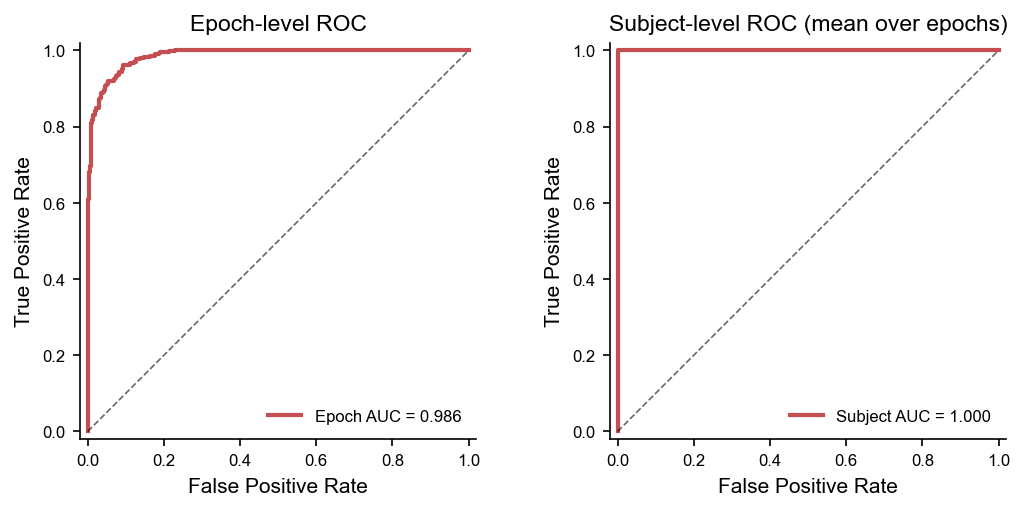

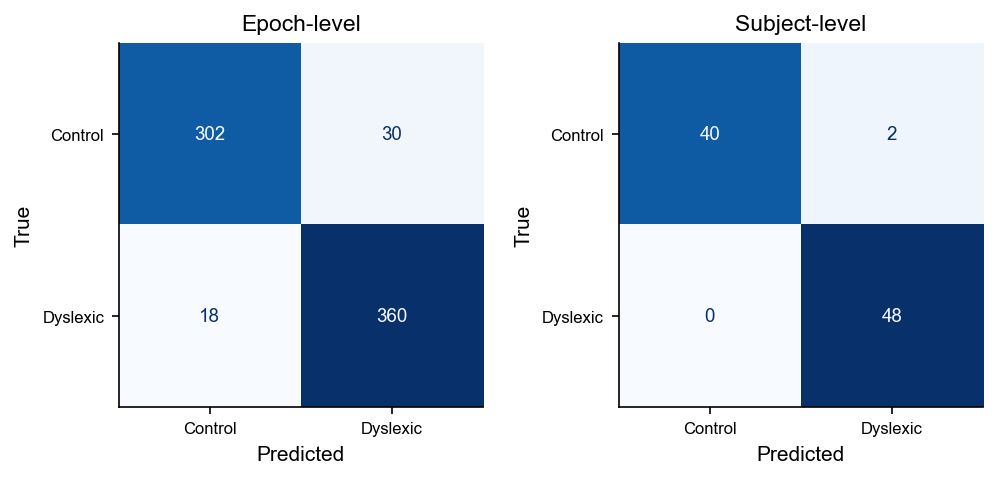

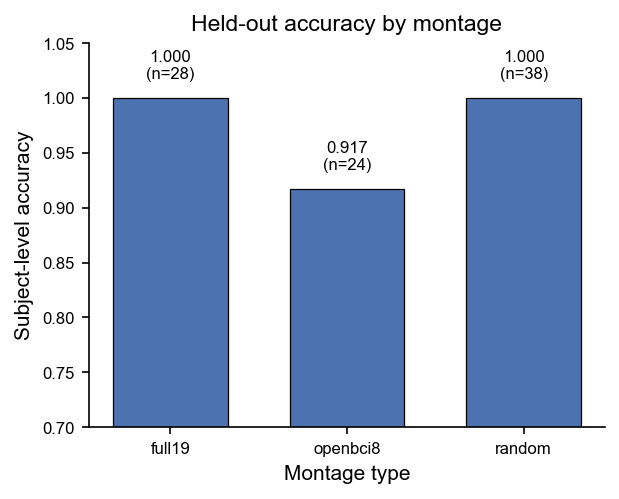

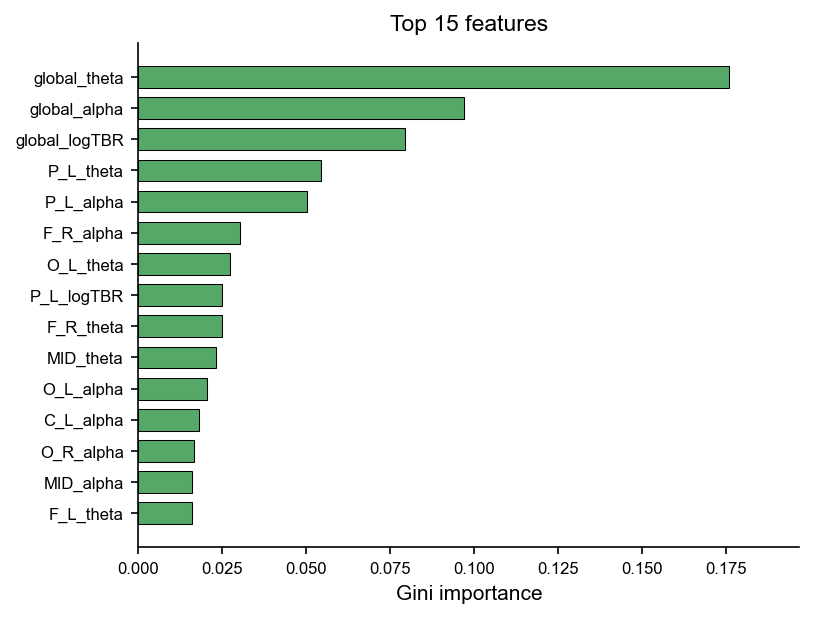

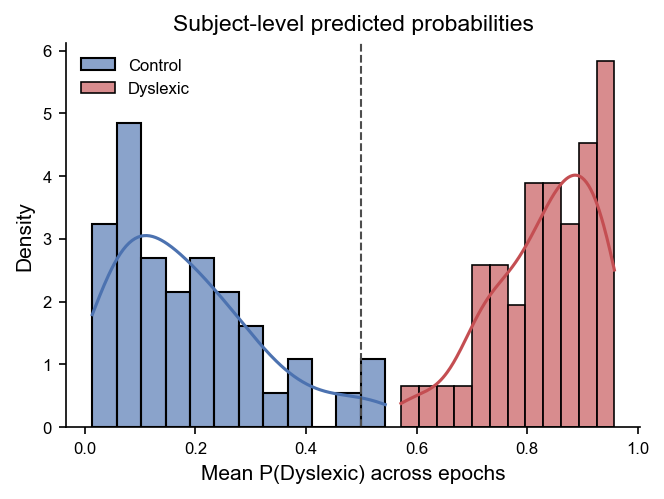

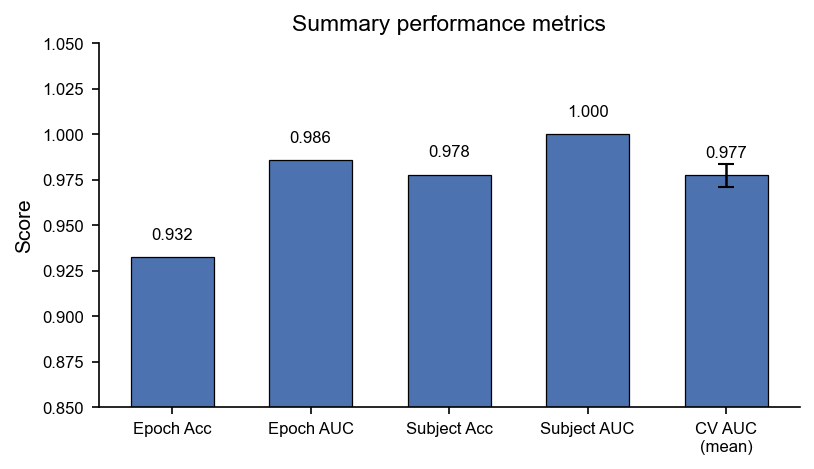

All figures saved to C:\Users\RTX2080Ti\Desktop\ex\ML viz\figures


In [10]:
# =============================================================================
# Publication-quality result figures (Q1 style)
# Run after cells 4–6 so that X, y_ep, g_ep, cleaning_model, identification_model,
# train_idx, test_idx, p_test, y_test, g_test, subjects, subj_p, subj_y,
# subj_kind, cv, ep_acc, ep_auc, subj_acc, subj_auc are available.
# =============================================================================

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.metrics import (roc_curve, auc, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance
import numpy as np

# --- global style -----------------------------------------------------------
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica"],
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
})

PALETTE = {"Control": "#4C72B0", "Dyslexic": "#C44E52", "accent": "#55A868"}
sns.set_palette([PALETTE["Control"], PALETTE["Dyslexic"]])

OUT = Path.cwd() / "figures"
OUT.mkdir(exist_ok=True)

# ---------------------------------------------------------------------------
# 1. ROC curves (epoch-level + subject-level)
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.4))

# Epoch-level
fpr_e, tpr_e, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr_e, tpr_e, color=PALETTE["Dyslexic"], lw=2,
             label=f"Epoch AUC = {ep_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8, alpha=0.6)
axes[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate",
            title="Epoch-level ROC", xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
axes[0].legend(loc="lower right", frameon=False)

# Subject-level
fpr_s, tpr_s, _ = roc_curve(subj_y, subj_p)
axes[1].plot(fpr_s, tpr_s, color=PALETTE["Dyslexic"], lw=2,
             label=f"Subject AUC = {subj_auc:.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8, alpha=0.6)
axes[1].set(xlabel="False Positive Rate", ylabel="True Positive Rate",
            title="Subject-level ROC (mean over epochs)",
            xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
axes[1].legend(loc="lower right", frameon=False)

for ax in axes:
    ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(OUT / "fig1_roc.png")
fig.savefig(OUT / "fig1_roc.pdf")
plt.show()

# ---------------------------------------------------------------------------
# 2. Confusion matrices (epoch + subject)
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(6.8, 3.2))

cm_e = confusion_matrix(y_test, p_test > 0.5)
cm_s = confusion_matrix(subj_y, subj_p > 0.5)

for ax, cm, title in zip(axes, [cm_e, cm_s],
                         ["Epoch-level", "Subject-level"]):
    disp = ConfusionMatrixDisplay(cm, display_labels=["Control", "Dyslexic"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

fig.tight_layout()
fig.savefig(OUT / "fig2_confusion.png")
fig.savefig(OUT / "fig2_confusion.pdf")
plt.show()

# ---------------------------------------------------------------------------
# 3. Subject-level accuracy by montage type
# ---------------------------------------------------------------------------
montage_order = ["full19", "openbci8", "random"]
acc_by_montage = []
n_by_montage = []
for k in montage_order:
    sel = np.array([subj_kind[s] == k for s in subjects])
    n = int(sel.sum())
    acc = accuracy_score(subj_y[sel], subj_p[sel] > 0.5) if n else np.nan
    acc_by_montage.append(acc)
    n_by_montage.append(n)

fig, ax = plt.subplots(figsize=(4.2, 3.4))
bars = ax.bar(montage_order, acc_by_montage, color="#4C72B0",
              edgecolor="k", linewidth=0.6, width=0.65)
ax.set_ylim(0.7, 1.05)
ax.set_ylabel("Subject-level accuracy")
ax.set_xlabel("Montage type")
ax.set_title("Held-out accuracy by montage")
ax.axhline(0.5, color="0.5", ls="--", lw=0.8, alpha=0.7)

for bar, acc, n in zip(bars, acc_by_montage, n_by_montage):
    ax.text(bar.get_x() + bar.get_width()/2, acc + 0.015,
            f"{acc:.3f}\n(n={n})", ha="center", va="bottom", fontsize=8)

fig.tight_layout()
fig.savefig(OUT / "fig3_montage_accuracy.png")
fig.savefig(OUT / "fig3_montage_accuracy.pdf")
plt.show()

# ---------------------------------------------------------------------------
# 4. Top feature importances (Random Forest)
# ---------------------------------------------------------------------------
imp = identification_model.feature_importances_
top_n = 15
idx = np.argsort(imp)[::-1][:top_n]
names = [eeg.FEATURE_NAMES[i] for i in idx]
vals = imp[idx]

fig, ax = plt.subplots(figsize=(5.5, 4.2))
y_pos = np.arange(len(names))[::-1]
ax.barh(y_pos, vals, color="#55A868", edgecolor="k", linewidth=0.5, height=0.7)
ax.set_yticks(y_pos)
ax.set_yticklabels(names)
ax.set_xlabel("Gini importance")
ax.set_title(f"Top {top_n} features")
ax.set_xlim(0, vals.max() * 1.12)
fig.tight_layout()
fig.savefig(OUT / "fig4_feature_importance.png")
fig.savefig(OUT / "fig4_feature_importance.pdf")
plt.show()

# ---------------------------------------------------------------------------
# 5. Probability distributions (subject-level)
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(4.5, 3.4))
sns.histplot(subj_p[subj_y == 0], bins=12, kde=True, stat="density",
             color=PALETTE["Control"], label="Control", alpha=0.65, ax=ax)
sns.histplot(subj_p[subj_y == 1], bins=12, kde=True, stat="density",
             color=PALETTE["Dyslexic"], label="Dyslexic", alpha=0.65, ax=ax)
ax.axvline(0.5, color="0.3", ls="--", lw=1)
ax.set_xlabel("Mean P(Dyslexic) across epochs")
ax.set_ylabel("Density")
ax.set_title("Subject-level predicted probabilities")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "fig5_prob_dist.png")
fig.savefig(OUT / "fig5_prob_dist.pdf")
plt.show()

# ---------------------------------------------------------------------------
# 6. Cross-validation summary + held-out metrics (table-like bar)
# ---------------------------------------------------------------------------
metrics = {
    "Epoch Acc": ep_acc,
    "Epoch AUC": ep_auc,
    "Subject Acc": subj_acc,
    "Subject AUC": subj_auc,
    "CV AUC\n(mean)": cv.mean(),
}
fig, ax = plt.subplots(figsize=(5.5, 3.2))
x = np.arange(len(metrics))
bars = ax.bar(x, list(metrics.values()), color="#4C72B0",
              edgecolor="k", linewidth=0.6, width=0.6)
ax.set_xticks(x)
ax.set_xticklabels(list(metrics.keys()))
ax.set_ylim(0.85, 1.05)
ax.set_ylabel("Score")
ax.set_title("Summary performance metrics")
for bar, v in zip(bars, metrics.values()):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.008,
            f"{v:.3f}", ha="center", va="bottom", fontsize=8)
# CV error bar
ax.errorbar(4, cv.mean(), yerr=cv.std(), fmt="none", ecolor="k",
            capsize=4, lw=1.2)
fig.tight_layout()
fig.savefig(OUT / "fig6_summary_metrics.png")
fig.savefig(OUT / "fig6_summary_metrics.pdf")
plt.show()

# ---------------------------------------------------------------------------
# 7. (Optional) Permutation importance on held-out data – more robust
# ---------------------------------------------------------------------------
# Uncomment if you want a more expensive but preferred importance ranking
# result = permutation_importance(identification_model, X_test, y_test,
#                                 n_repeats=10, random_state=SEED, n_jobs=-1,
#                                 scoring="roc_auc")
# perm_imp = result.importances_mean
# idx = np.argsort(perm_imp)[::-1][:15]
# ... same plotting code as Fig. 4

print(f"All figures saved to {OUT.resolve()}")

C:\Users\RTX2080Ti\AppData\Local\Temp\ipykernel_17860\722643062.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_subj, x="True label", y="P_Dyslexic",


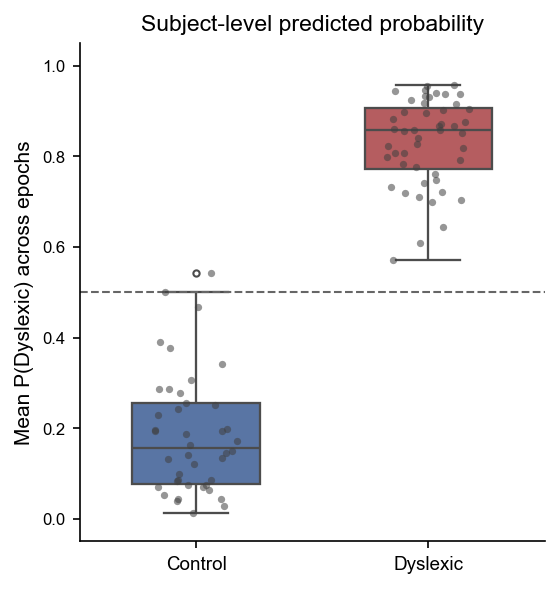

C:\Users\RTX2080Ti\AppData\Local\Temp\ipykernel_17860\722643062.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x="True label", y="P_Dyslexic",
C:\Users\RTX2080Ti\AppData\Local\Temp\ipykernel_17860\722643062.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x="True label", y="P_Dyslexic",
C:\Users\RTX2080Ti\AppData\Local\Temp\ipykernel_17860\722643062.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x="True label", y="P_Dyslexic",


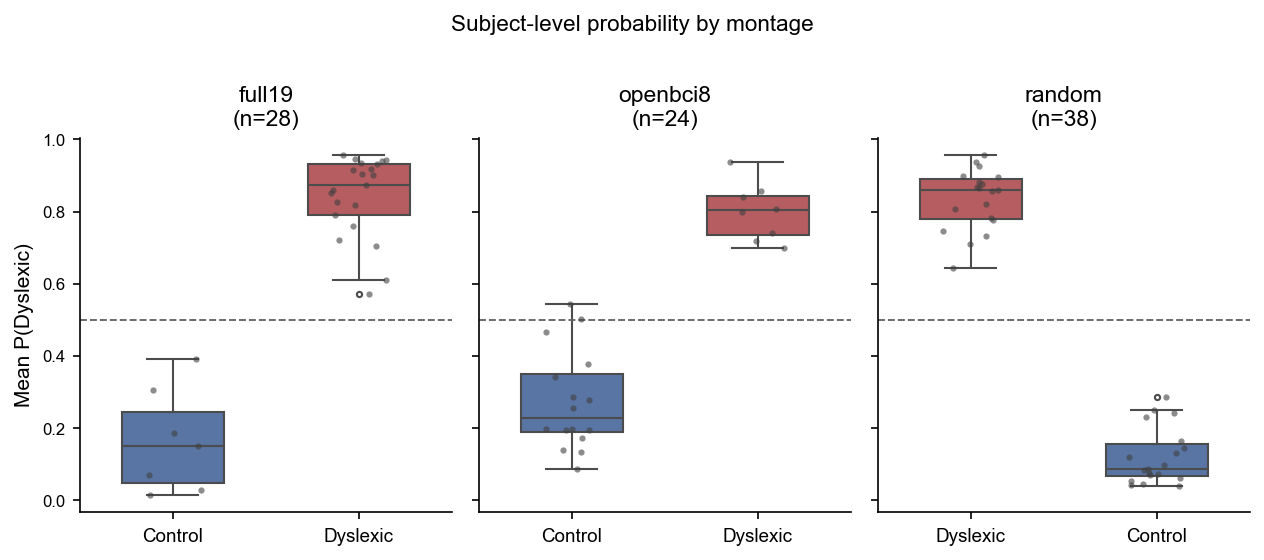

C:\Users\RTX2080Ti\AppData\Local\Temp\ipykernel_17860\722643062.py:101: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x="Class", y="Value", palette=PAL,
C:\Users\RTX2080Ti\AppData\Local\Temp\ipykernel_17860\722643062.py:101: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x="Class", y="Value", palette=PAL,
C:\Users\RTX2080Ti\AppData\Local\Temp\ipykernel_17860\722643062.py:101: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x="Class", y="Value", palette=PAL,
C:\Users\RTX2080Ti\AppData\Local\Temp\ipykernel_17860\7226

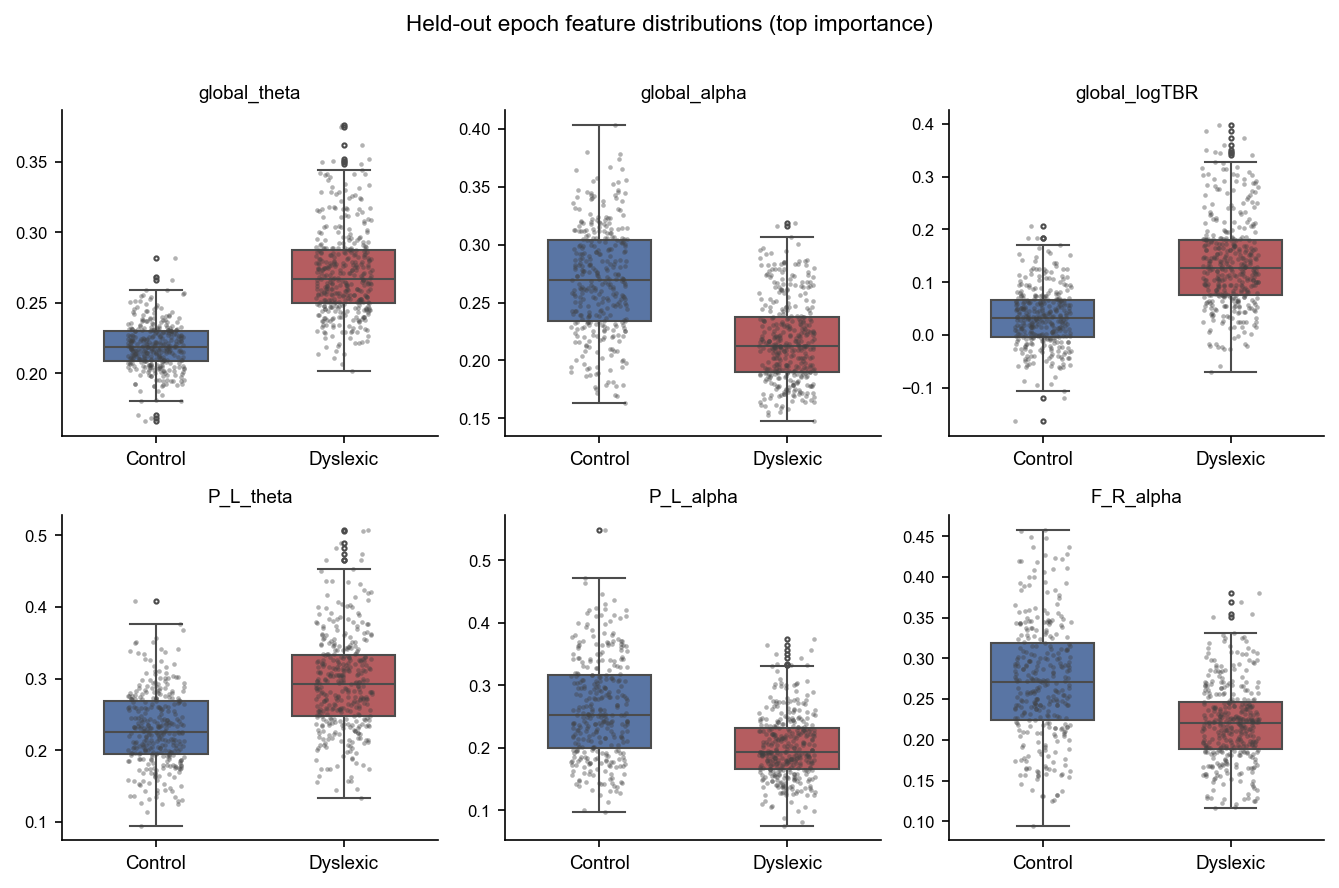

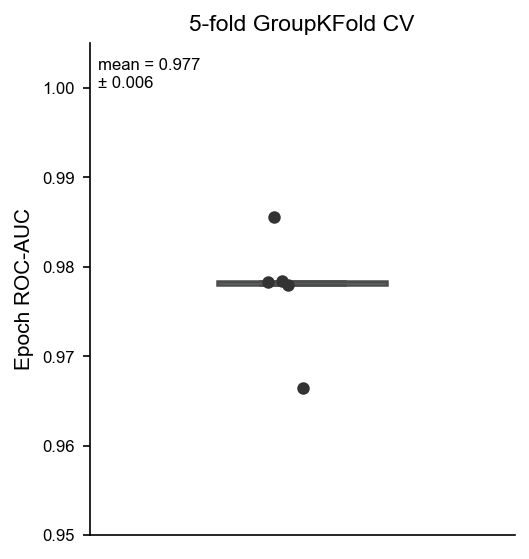

C:\Users\RTX2080Ti\AppData\Local\Temp\ipykernel_17860\722643062.py:147: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_conf, x="Outcome", y="Confidence",


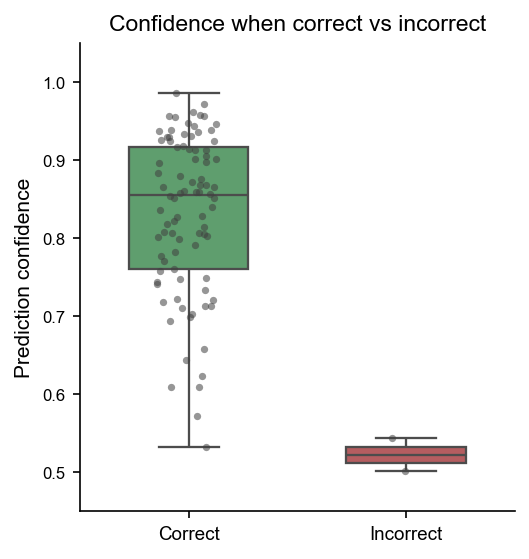

Box-plot figures saved to C:\Users\RTX2080Ti\Desktop\ex\ML viz\figures


In [11]:
# =============================================================================
# Box-plot suite for results evaluation (Q1 style)
# =============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path

# style
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

PAL = {"Control": "#4C72B0", "Dyslexic": "#C44E52"}
OUT = Path.cwd() / "figures"
OUT.mkdir(exist_ok=True)

# ---------------------------------------------------------------------------
# 1. Subject-level P(Dyslexic) by true class
# ---------------------------------------------------------------------------
df_subj = pd.DataFrame({
    "P_Dyslexic": subj_p,
    "True label": ["Control" if y == 0 else "Dyslexic" for y in subj_y],
    "Montage": [subj_kind[s] for s in subjects]
})

fig, ax = plt.subplots(figsize=(3.8, 4.0))
sns.boxplot(data=df_subj, x="True label", y="P_Dyslexic",
            palette=PAL, width=0.55, fliersize=3, linewidth=1.1, ax=ax)
sns.stripplot(data=df_subj, x="True label", y="P_Dyslexic",
              color="0.25", size=3.5, alpha=0.55, jitter=0.18, ax=ax)
ax.axhline(0.5, color="0.4", ls="--", lw=1)
ax.set_ylabel("Mean P(Dyslexic) across epochs")
ax.set_xlabel("")
ax.set_title("Subject-level predicted probability")
ax.set_ylim(-0.05, 1.05)
fig.tight_layout()
fig.savefig(OUT / "box1_subject_prob.png")
fig.savefig(OUT / "box1_subject_prob.pdf")
plt.show()

# ---------------------------------------------------------------------------
# 2. Same, but split by montage (optional multi-panel)
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(8.5, 3.6), sharey=True)
for ax, mont in zip(axes, ["full19", "openbci8", "random"]):
    sub = df_subj[df_subj["Montage"] == mont]
    sns.boxplot(data=sub, x="True label", y="P_Dyslexic",
                palette=PAL, width=0.55, fliersize=2.5, linewidth=1.0, ax=ax)
    sns.stripplot(data=sub, x="True label", y="P_Dyslexic",
                  color="0.25", size=3, alpha=0.6, jitter=0.15, ax=ax)
    ax.axhline(0.5, color="0.4", ls="--", lw=0.9)
    ax.set_title(f"{mont}\n(n={len(sub)})")
    ax.set_xlabel("")
    ax.set_ylabel("Mean P(Dyslexic)" if ax is axes[0] else "")
fig.suptitle("Subject-level probability by montage", y=1.02)
fig.tight_layout()
fig.savefig(OUT / "box2_prob_by_montage.png")
fig.savefig(OUT / "box2_prob_by_montage.pdf")
plt.show()

# ---------------------------------------------------------------------------
# 3. Top features by class (epoch-level, held-out)
# ---------------------------------------------------------------------------
# Reconstruct cleaned features for the test set
X_test_raw = X[test_idx]          # before cleaning
feat_names = eeg.FEATURE_NAMES
top_feats = ["global_theta", "global_alpha", "global_logTBR",
             "P_L_theta", "P_L_alpha", "F_R_alpha"]

# Build a long dataframe
rows = []
for i, name in enumerate(feat_names):
    if name not in top_feats:
        continue
    for val, lab in zip(X_test_raw[:, i], y_test):
        if np.isnan(val):
            continue
        rows.append({"Feature": name, "Value": val,
                     "Class": "Control" if lab == 0 else "Dyslexic"})
df_feat = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 3, figsize=(9.0, 5.8))
axes = axes.ravel()
for ax, feat in zip(axes, top_feats):
    sub = df_feat[df_feat["Feature"] == feat]
    sns.boxplot(data=sub, x="Class", y="Value", palette=PAL,
                width=0.55, fliersize=2, linewidth=1.0, ax=ax)
    sns.stripplot(data=sub, x="Class", y="Value",
                  color="0.25", size=2.2, alpha=0.4, jitter=0.15, ax=ax)
    ax.set_title(feat, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Held-out epoch feature distributions (top importance)", y=1.01)
fig.tight_layout()
fig.savefig(OUT / "box3_top_features.png")
fig.savefig(OUT / "box3_top_features.pdf")
plt.show()

# ---------------------------------------------------------------------------
# 4. Cross-validation ROC-AUC across folds
# ---------------------------------------------------------------------------
df_cv = pd.DataFrame({"ROC-AUC": cv, "Fold": [f"Fold {i+1}" for i in range(len(cv))]})

fig, ax = plt.subplots(figsize=(3.6, 3.8))
sns.boxplot(y="ROC-AUC", data=df_cv, color="#55A868", width=0.4,
            fliersize=0, linewidth=1.2, ax=ax)
sns.stripplot(y="ROC-AUC", data=df_cv, color="0.2", size=6, ax=ax)
ax.set_ylim(0.95, 1.005)
ax.set_ylabel("Epoch ROC-AUC")
ax.set_title("5-fold GroupKFold CV")
ax.set_xticks([])
# annotate mean ± sd
ax.text(0.02, 0.97, f"mean = {cv.mean():.3f}\n± {cv.std():.3f}",
        transform=ax.transAxes, va="top", fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "box4_cv_auc.png")
fig.savefig(OUT / "box4_cv_auc.pdf")
plt.show()

# ---------------------------------------------------------------------------
# 5. Model confidence when correct vs incorrect (subject level)
# ---------------------------------------------------------------------------
correct = (subj_p > 0.5) == (subj_y == 1)
confidence = np.maximum(subj_p, 1 - subj_p)   # distance from 0.5

df_conf = pd.DataFrame({
    "Confidence": confidence,
    "Outcome": np.where(correct, "Correct", "Incorrect")
})

fig, ax = plt.subplots(figsize=(3.6, 3.8))
sns.boxplot(data=df_conf, x="Outcome", y="Confidence",
            palette={"Correct": "#55A868", "Incorrect": "#C44E52"},
            width=0.55, fliersize=3, linewidth=1.1, ax=ax)
sns.stripplot(data=df_conf, x="Outcome", y="Confidence",
              color="0.25", size=3.5, alpha=0.55, jitter=0.15, ax=ax)
ax.set_ylabel("Prediction confidence")
ax.set_xlabel("")
ax.set_title("Confidence when correct vs incorrect")
ax.set_ylim(0.45, 1.05)
fig.tight_layout()
fig.savefig(OUT / "box5_confidence.png")
fig.savefig(OUT / "box5_confidence.pdf")
plt.show()

print(f"Box-plot figures saved to {OUT.resolve()}")